<table>
  <tr>
    <td><div align="left"><font size="30">Chapter 3:<br>Time and Motion</font></div></td>
    <td><img src="https://github.com/petercorke/RVC3-python/raw/main/figures/RVC3P-cover.png?raw=1" width="200"></td>
  </tr>
</table>

<span style="font-size:150%">Robotics, Vision & Control 3e: for Python</span>

Copyright © 2021- Peter Corke

In [8]:
try:
    from google.colab import output
    print('Running on CoLab')
    output.enable_custom_widget_manager()
    !pip install ipympl
    !pip install spatialmath-python
    !pip install roboticstoolbox-python>=1.0.2
    !pip install --no-deps rvc3python
    COLAB = True

except ModuleNotFoundError:
    COLAB = False

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "last_expr_or_assign"

%matplotlib widget

In [9]:
from IPython.display import HTML

import urllib.request

# add RTB examples folder to the path
import sys, os.path
import roboticstoolbox as rtb
import RVC3
# sys.path.append(os.path.join(rtb.__path__[0], 'examples'))
sys.path.append(os.path.join(RVC3.__path__[0], 'examples'))

# standard imports
import numpy as np
from scipy import linalg
import matplotlib.pyplot as plt
import math
from math import pi
np.set_printoptions(
    linewidth=120, formatter={
        'float': lambda x: f"{0:8.4g}" if abs(x) < 1e-10 else f"{x:8.4g}"})
np.random.seed(0)
from spatialmath import *
from spatialmath.base import *
from roboticstoolbox import quintic, trapezoidal, mtraj, mstraj, xplot, ctraj

There are some minor code changes compared to the book. These are to support 
the Matplotlib widget (ipympl) backend.  This allows 3D plots to be rotated
so the changes are worthwhile.

# 3.1 Time-Varying Pose


## 3.1.1 Rate of Change of Orientation

Recall that any transformation in 3D can be described by
$${}^A\mathbf{R}_B=e^{\theta(t)[{}^A\hat{\mathbf{\omega}}_B(t)]_\times} \in \mathrm{SO}(3)$$
where ${}^A\hat{\mathbf{\omega}}_B(t)$ is the rotational axis, $\theta(t)$ is the rotational angle, and $[\cdot]_\times$ is a skew-symmetric matrix.

The derivative at time $t$ for the rotation matrix ${}^A\mathbf{R}_B$ is 
$${}^A\dot{\mathbf{R}}_B = [{}^A\hat{\mathbf{\omega}}_B]_\times {}^A\mathbf{R}_B\in \mathbb{R}^{3 \times 3},$$
a general $3\times 3$ matrix, where ${}^A{\mathbf{\omega}}_B=\dot\theta{}^A\hat{\mathbf{\omega}}_B$ is the *angular velocity* of frame $\{B\}$ with respect to frame $\{A\}$.
This vector ${}^A{\mathbf{\omega}}_B=(\omega_x, \omega_y, \omega_z)$ defines the instantaneous axis and rate ($\|{}^A{\mathbf{\omega}}_B\|$) of rotation.

If angular velocity is measured in the moving frame $\{B\}$, we can show that
$${}^A\dot{\mathbf{R}}_B = {}^A\mathbf{R}_B [{}^B{\mathbf{\omega}}_B]_\times \in \mathbb{R}^{3 \times 3} ,$$
which has the order of the rotation matrix and the skew-symmetric matrix swapped compared to above.

## 3.1.2 Rate of Change of Pose

Recall that we can express pose by
$${}^A\mathbf{T}_B =
\begin{pmatrix}
{}^A\mathbf{R}_B & {}^A\mathbf{t}_B \\
\mathbf{0}_{1\times 3} & 1
\end{pmatrix}
\in \mathrm{SE}(3).$$
The derivative with respect to time is
$${}^A\dot{\mathbf{T}}_B =
\begin{pmatrix}
{}^A\dot{\mathbf{R}}_B & {}^A\dot{\mathbf{t}}_B \\
\mathbf{0}_{1\times 3} & 0
\end{pmatrix}
=
\begin{pmatrix}
[{}^A\boldsymbol{\omega}_B]_\times \, {}^A\mathbf{R}_B & {}^A\dot{\mathbf{t}}_B \\
\mathbf{0}_{1\times 3} & 0
\end{pmatrix}
\in \mathbb{R}^{4\times 4}.$$
The rate of change can be described in terms of the current orientation ${}^A\boldsymbol{\omega}_B$ and two velocities: the angular velocity ${}^A{\mathbf{\omega}}_B\in\mathbb R^3$ as above and the *translational (or linear) velocity* ${}^A{\mathbf{v}}_B={}^A{\dot{\mathbf t}}_B \in\mathbb R^3$.
These can be combined to create the *spatial velocity vector*
$$
{}^A{\mathbf{\nu}}_B = ({}^A{\mathbf{v}}_B, {}^A{\mathbf{\omega}}_B) \in\mathbb R^6,
$$
which is the instantaneous velocity of frame $\{B\}$ with respect to frame $\{A\}$.
(NB: this is $\nu$, nu, not v!)

Every point in the body has the same angular velocity but different translational velocity.
It is common to place $\{B\}$ at the centre of mass.

## 3.1.3 Transforming Spatial Velocities


![fig-31-transforming-velocities.png](fig-31-transforming-velocities.png)

Consider the situation in fig. 3.1a, with two fixed frames $\{A\}$ and $\{B\}$, and a moving coordinate frame.
To express the spatial velocity ${}^A{\mathbf{\nu}}$ in terms of the spatial velocity observed from frame $\{B\}$, that is ${}^B{\mathbf{\nu}}$, we have
$$
{}^{A}\boldsymbol{\nu}
=
\begin{pmatrix}
{}^{A}\mathbf{R}_{B} & \mathbf{0}_{3\times3}\\
\mathbf{0}_{3\times3} & {}^{A}\mathbf{R}_{B}
\end{pmatrix}
{}^{B}\boldsymbol{\nu}
=
{}^{A}\mathbf{J}_{B}\left({}^{A}\mathbf{T}_{B}\right)
{}^{B}\boldsymbol{\nu}
$$
where ${}^{A}\mathbf{J}_{B}(\cdot)$ is a Jacobian or interaction matrix which is a function of the relative orientation of the two frames, and independent of the translation between them.

We can investigate this setup numerically:

In [10]:
aTb = SE3.Tx(-2) * SE3.Rz(-pi/2) * SE3.Rx(pi/2)

   0         0        -1        -2         
  -1         0         0         0         
   0         1         0         0         
   0         0         0         1         


In [11]:
bV = [1, 2, 3, 4, 5, 6] # spatial velocity in {B}

[1, 2, 3, 4, 5, 6]

In [12]:
aJb = aTb.jacob()
print(aJb.shape)
aV = aJb @ bV # spatial velocity in {A}

(6, 6)


array([      -3,       -1,        2,       -6,       -4,        5])

Note that the velocities have been transposed and sometimes negated due to the different orientation.

Next, consider fig. 3.1b where the two frames are rigidly attached and moving together.
The observed spatial velocities with respect to each frame are related by
$$
{}^{A}\boldsymbol{\nu}
=
\begin{pmatrix}
{}^{A}\mathbf{R}_{B} &
\left[{}^{A}\mathbf{t}_{B}\right]_{\times}\,{}^{A}\mathbf{R}_{B}\\
\mathbf{0}_{3\times3} &
{}^{A}\mathbf{R}_{B}
\end{pmatrix}
{}^{B}\boldsymbol{\nu}
=
\operatorname{Ad}\left({}^{A}\mathbf{T}_{B}\right)
{}^{B}\boldsymbol{\nu}
$$
which uses the adjoint matrix of the relative pose, and *does* depend on translation between frames.

In [13]:
aV = aTb.Ad() @ [1, 2, 3, 0, 0, 0] # pure translation

array([      -3,       -1,        2,        0,        0,        0])

In [14]:
aV = aTb.Ad() @ [0, 0, 0, 1, 0, 0] # pure rotation about x-axis

array([       0,        0,        2,        0,       -1,        0])

In [15]:
aV = aTb.Ad() @ [1, 2, 3, 1, 0, 0] # combining both above

array([      -3,       -1,        4,        0,       -1,        0])

NB: spatial velocity as defined here is often referred to as a twist.
This is *not* the same as the twists introduced in chapter 2.

## 3.1.4 Incremental Rotation


Often we need to integrate angular velocity, measured by sensors in the body frame, to estimate its orientation.
Assuming that the rotational axis is constant over the sample interval $\delta_t$, a computationally cheap approximation of the rotation $\mathbf R^\Delta\in\mathrm{SO(3)}$ from time step $t$ to $t+\delta_t$ is given by
$$
\mathbf{R}^{\Delta}
\approx
\delta_t
\left[{}^{B}\boldsymbol{\omega}\right]_{\times}
+
\mathbf{1}_{3\times3}
$$
(ie, a small rotation can be approximated by sum of $I$ and a skew-symmetric matrix) and illustrated by the example:

In [16]:
rotx(0.001)

array([[       1,        0,        0],
       [       0,        1,   -0.001],
       [       0,    0.001,        1]])

Rearranging gives us the angular velocity vector
$$
\boldsymbol{\omega} \approx \frac{1}{\delta_t}\vee_\times \left(
\mathbf{R}^\top_{B\langle t\rangle}\mathbf{R}_{B\langle t+\delta_t\rangle}
-\mathbf{1}_{3\times3}
\right)
$$
and so
$$
\mathbf{R}_{B\langle t+\delta_t\rangle}
\approx
\mathbf{R}_{B\langle t\rangle}
\left(
\mathbf{1}_{3\times3}
+\delta_t[\boldsymbol{\omega}]_\times
\right),
$$
which is cheap to compute (compared to the matrix exponential) and involves no trigonometric operations.
The tradeoffs are shown below:

In [17]:
import time
Rexact = np.eye(3); Rapprox = np.eye(3);  # null rotation
w = np.array([1, 0, 0]);   # rotation of 1rad/s about x-axis
dt = 0.01;                 # time step

# exact integration over 100 time steps
t0 = time.process_time();
for i in range(100):
  Rexact = Rexact @ trexp(skew(w*dt));  # update by composition
print(time.process_time() - t0)

# approximate integration over 100 time steps
t0 = time.process_time();
for i in range(100):
  Rapprox = Rapprox + Rapprox @ skew(w*dt);  # update by addition
print(time.process_time() - t0)

0.015625
0.0


In [18]:
np.linalg.det(Rapprox) - 1 # a significant error

np.float64(0.010049662092876055)

In [19]:
np.linalg.det(Rexact) - 1 # much smaller error

np.float64(-2.886579864025407e-15)

We check the overall result:

In [20]:
tr2angvec(trnorm(Rexact))

(1.0, array([       1,        0,        0]))

In [21]:
tr2angvec(trnorm(Rapprox))

(0.999966668666524, array([       1,        0,        0]))

The approximate solution is good to 4 sf.
Note that the sample time used in this example is also quite high.

A unit quaternion derivative can also be approximated by a first-order difference, even cheaper to compute than rotation matrix approach.

NB addition is not a group operation for $\mathrm{SO}(3)$, nor for $\mathbb H$, but for small values of $\delta_t$ (i.e., high sample rate) this problem can be corrected by normalisation as in 2.4.6.
There is a tradeoff on low-end hardware.

## 3.1.5 Incremental Rigid-Body Motion

Consider two poses of infinitesimal difference which are related by $\mathbf\xi_2 = \mathbf\xi_1 \oplus \mathbf\xi^\Delta$.
Using the $\mathrm{SE}(3)$ matrix representation, we can write
$$
\mathbf T^\Delta := \mathbf T_1^{-1}\mathbf T_2
= \begin{pmatrix}
\mathbf R^\Delta & \mathbf t^\Delta\\
\mathbf 0_{1\times 3} & 1
\end{pmatrix}
$$
where $\mathbf t^\Delta\in\mathbb R^3$ is an incremental displacement.
$\mathbf R^\Delta$ is an incremental rotation matrix, which as shown in 3.1.4, has just three unique elements: $\mathbf r^\Delta:=\vee_\times (\mathbf R^\Delta-\mathbf 1_{3\times 3})$.
Hence only six parameters are required to describe the whole motion, a *spatial displacement*:
$$
\Delta(\boldsymbol{\xi}_1,\boldsymbol{\xi}_2)\mapsto\boldsymbol{\delta}
= (\mathbf t^\Delta, \mathbf r^\Delta)\in\mathbb R^6.
$$
A body with constant spatial velocity $\boldsymbol\nu$ for $\delta_t$ seconds undergoes a spatial displacement of $\boldsymbol{\delta}=\delta_t\boldsymbol{\nu}$, which is an approximation for $\vee(\log\mathbf T^\Delta)$.
Then we have
$$
\mathbf T^\Delta
= \begin{pmatrix}
[\mathbf r^\Delta]_\times + \mathbf 1_{3\times 3} & \mathbf t^\Delta\\
\mathbf 0_{1\times 3} & 1
\end{pmatrix}
$$
which is an approximation to $\mathrm e^{[\boldsymbol\delta]}$.

In [22]:
# Compare first-order differential motion with the exact matrix logarithm/exponential.
T1 = SE3()
T2 = SE3(1, 2, 3)
T0 = trotx(0.3, t=[2, 3, 4])
poses = (
    ("T1 to T2", np.array(T1), np.array(T2)),
    ("T0 to T2", np.array(T0), np.array(T2)),
)

for name, T_start, T_end in poses:
    T_relative = np.linalg.inv(T_start) @ T_end
    delta = tr2delta(T_start, T_end)
    T_approx = delta2tr(delta)

    log_T_relative = linalg.logm(T_relative)
    log_delta = np.r_[log_T_relative[:3, 3], vex(log_T_relative[:3, :3])]
    T_exact = linalg.expm(log_T_relative)

    print(f"{name}:")
    print("  tr2delta:         ", delta)
    print("  logm coordinates: ", log_delta)
    print("  delta2tr error:   ", np.linalg.norm(T_approx - T_relative))
    print("  expm(logm) error: ", np.linalg.norm(T_exact - T_relative))


T1 to T2:
  tr2delta:          [       1        2        3        0        0        0]
  logm coordinates:  [       1        2        3        0        0        0]
  delta2tr error:    0.0
  expm(logm) error:  0.0
T0 to T2:
  tr2delta:          [      -1   -1.251  -0.6598  -0.2955        0        0]
  logm coordinates:  [      -1   -1.142  -0.8425     -0.3        0        0]
  delta2tr error:    0.06316374282176608
  expm(logm) error:  3.554447978966673e-16


# 3.2 Accelerating Bodies and Reference Frames


We move from considering only first derivative (velocity) to second derivative (acceleration).
This is dynamics.

## 3.2.1 Dynamics of Moving Bodies


For translation, Newton's second law for a particle in the inertial frame $\{0\}$, with position $\mathbf x$ and mass $m$, due to the applied force ${}^{0}\mathbf{f}_B$:
$$
m\,{}^{0}\ddot{\mathbf{x}}_B = {}^{0}\mathbf{f}_B.
$$

For rotation in 3D, Euler's equations of motion:
$$
{}^{B}\mathbf{J}_B\,{}^{B}\dot{\boldsymbol{\omega}}_B
+ {}^{B}\boldsymbol{\omega}_B \times
\left({}^{B}\mathbf{J}_B\,{}^{B}\boldsymbol{\omega}_B\right)
= {}^{B}\boldsymbol{\tau}_B
$$
where ${}^{B}\boldsymbol{\omega}_B$ is the angular velocity of the body, ${}^{B}\boldsymbol{\tau}_B$ is the applied torque or moment, ${}^{B}\mathbf{J}_B\in\mathbb R^{3\times 3}$ is a rotational inertia tensor (which is always symmetric and positive definite).

In the example below, the nonzero off-diagonal elements of `J` will cause the body to tumble.

In [23]:
J = np.array([[ 2, -1, 0],
              [-1,  4, 0],
              [ 0,  0, 3]])
orientation = UnitQuaternion()  # identity quaternion
w = 0.2 * np.array([1, 2, 2])

array([     0.2,      0.4,      0.4])

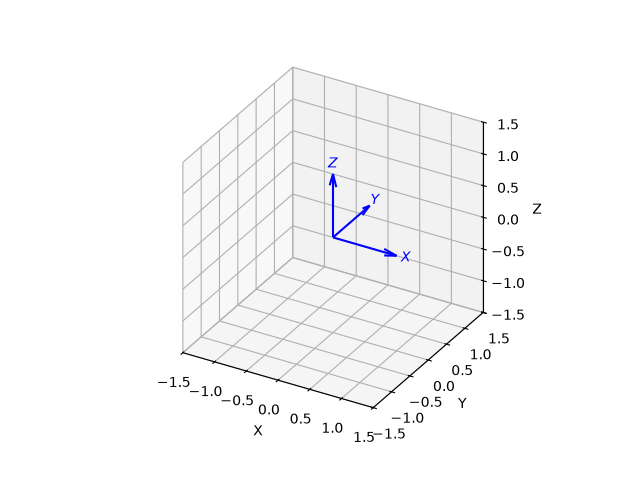

In [24]:
dt = 0.05  # time step
def update():
  global orientation, w
  for t in np.arange(0, 10, dt):
     wd = -np.linalg.inv(J) @ (np.cross(w, J @ w))  # (3.12)
     w += wd * dt
     orientation *= UnitQuaternion.EulerVec(w * dt)
     yield orientation.R

plotvol3(new=True);
tranimate(update(), dim=1.5);
# HTML(tranimate(update(), dim=1.5, movie=True))

## 3.2.2 Transforming Forces and Torques


The *wrench* $\mathbf w$ is defined by combining the translational force $\mathbf f = (f_x, f_y, f_z)$ with the rotational torque (moment) $\mathbf m = (m_x, m_y, m_z)$:
$$
\mathbf w := (f_x, f_y, f_z, m_x, m_y, m_z) \in\mathbb R^6.
$$

For two coordinate frames $\{A\}$ and $\{B\}$ attached to the same body, the wrenches ${}^{A}\mathbf{w}$ and ${}^{B}\mathbf{w}$ applied at the origin of those frames are related by:
$$
{}^{A}\mathbf{w}
=
\begin{pmatrix}
{}^{B}\mathbf{R}_{A} &
\left[{}^{B}\mathbf{t}_{A}\right]_{\times}
{}^{B}\mathbf{R}_{A}
\\
\mathbf{0}_{3\times 3} &
{}^{B}\mathbf{R}_{A}
\end{pmatrix}^{\mathsf{T}}
{}^{B}\mathbf{w}
=
\operatorname{Ad}^{\mathsf{T}}
\left({}^{B}\mathbf{T}_{A}\right)
{}^{B}\mathbf{w}
$$
cf 3.1.2, transforming spatial velocities, but note that this uses the transpose of adjoint of *inverse* relative pose.

The following example follows fig 3.1b.

In [25]:
bW = [1, 2, 3, 0, 0, 0]

[1, 2, 3, 0, 0, 0]

In [26]:
aW = aTb.inv().Ad().T @ bW

array([      -3,       -1,        2,        0,        4,        2])

NB: no set convention for wrench definition, could be $\mathbf w = (\mathbf m, \mathbf f)$ in other sources.

## 3.2.3 Inertial Reference Frame


An *inertial reference frame* is defined as a reference frame that is not accelerating or rotating.
For example, for a particle $P$ at rest wrt a stationary reference frame $\{0\}$, an inertial reference frame might be $\{B\}$ which is moving with constant velocity relative to $\{0\}$.

However, if $\{B\}$ were accelerating wrt $\{0\}$, then an observer in $\{B\}$ would have to invoke a fictitious force to explain the violation of Newton's first law.
An example of this *non*-inertial reference frame is being inside an accelerating vehicle.

For a reference frame rotating with angular velocity $\omega$ about its origin, Newton's second law becomes
$$
m\left(
{}^{B}\dot{\mathbf{v}}
+ \underbrace{\boldsymbol{\omega}\times
\left(\boldsymbol{\omega}\times{}^{B}\mathbf{p}\right)}_{\text{centripetal}}
+ \underbrace{2\boldsymbol{\omega}\times{}^{B}\mathbf{v}}_{\text{Coriolis}}
+ \underbrace{\dot{\boldsymbol{\omega}}\times{}^{B}\mathbf{p}}_{\text{Euler}}
\right)
= {}^{0}\mathbf{f}
$$

In robotics, "inertial frame" and "world coordinate frame" are generally used to indicate a frame fixed to some point on Earth, not on the body or vehicle.
The small Coriolis acceleration experienced by an Earth-bound observer is usually ignored.

# 3.3 Creating Time-Varying Pose


A common problem in robotics is creating a smooth path $\xi(s), s\in[0,1]$, from pose $\xi_0$ to $\xi_1$, such that $s(t)$ is a smooth function of time.

## 3.3.1 Smooth One-Dimensional Trajectories


We are looking for a smooth function with specified initial and final value (boundary conditions).
One obvious candidate is a polynomial, often of degree $5$ (because the six coefficients allow it to meet the six BCs on initial and final position, velocity, acceleration):
$$
q(t)=At^5+Bt^4+Ct^3+Dt^2+Et+F
$$
where $t\in[0,T]$.
We can write these equations as
$$
\begin{pmatrix}
q_0\\
q_T\\
\dot{q}_0\\
\dot{q}_T\\
\ddot{q}_0\\
\ddot{q}_T
\end{pmatrix}
=
\begin{pmatrix}
0 & 0 & 0 & 0 & 0 & 1\\
T^5 & T^4 & T^3 & T^2 & T & 1\\
0 & 0 & 0 & 0 & 1 & 0\\
5T^4 & 4T^3 & 3T^2 & 2T & 1 & 0\\
0 & 0 & 0 & 2 & 0 & 0\\
20T^3 & 12T^2 & 6T & 2 & 0 & 0
\end{pmatrix}
\begin{pmatrix}
A\\
B\\
C\\
D\\
E\\
F
\end{pmatrix}.
$$

In [27]:
traj = quintic(0, 1, np.linspace(0, 1, 50))

Trajectory created by quintic: 50 time steps x 1 axes

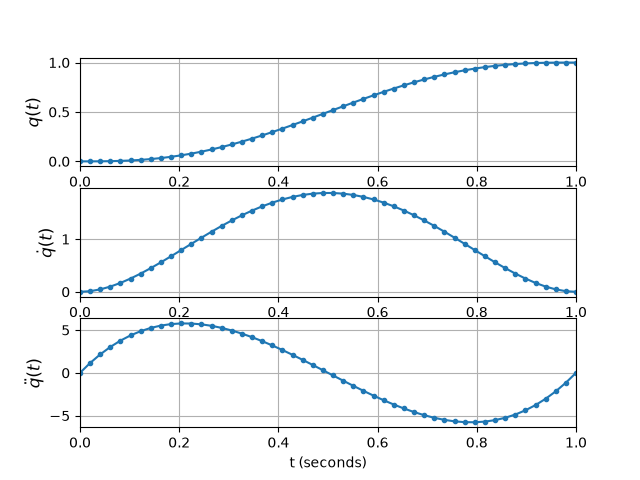

In [28]:
traj.plot();

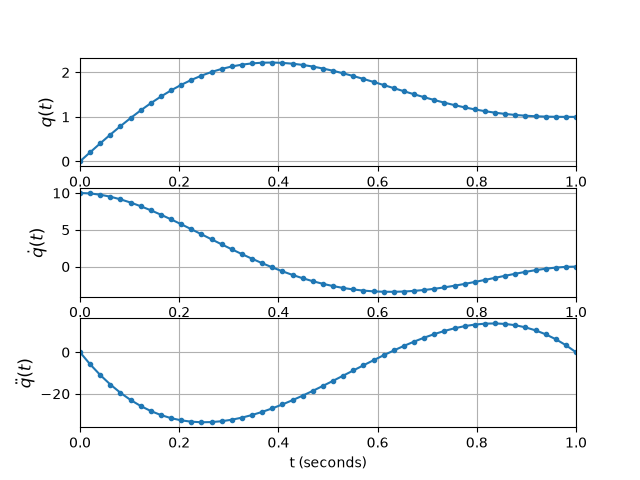

In [29]:
traj2 = quintic(0, 1, np.linspace(0, 1, 50), qd0=10, qdf=0);
traj2.plot();

Above is one problem with polynomials: nonzero initial velocity causes overshoot of terminal value (goes over 2 before coming back to 1).

In [30]:
qd = traj.qd;
qd.mean() / qd.max()

np.float64(0.5231022222222199)

Above is another problem with polynomials; mean velocity is only 52% of the peak, so not making full use of motor.
We want the top of the velocity curve to be flatter.

An alternative is a trapezoidal hybrid trajectory (so named for the shape of the velocity curve):

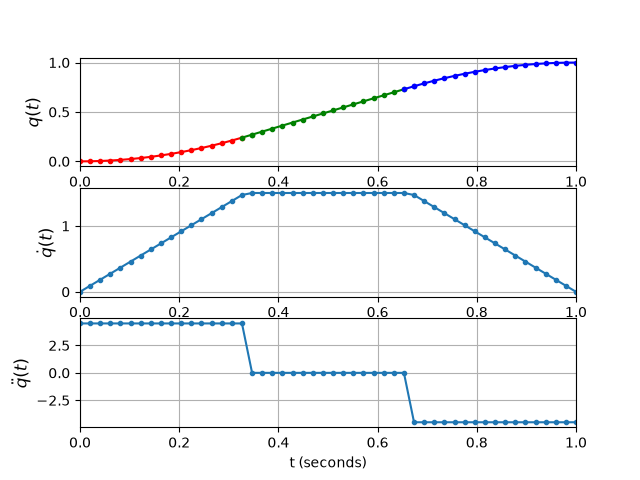

In [31]:
traj = trapezoidal(0, 1, np.linspace(0, 1, 50));
traj.plot();

Velocity is piecewise linear and continuous.
Position is straight lines with parabolic blends.
Acceleration is discontinuous.

In [32]:
traj.qd.max() # chosen by function, can be overriden as below

np.float64(1.5)

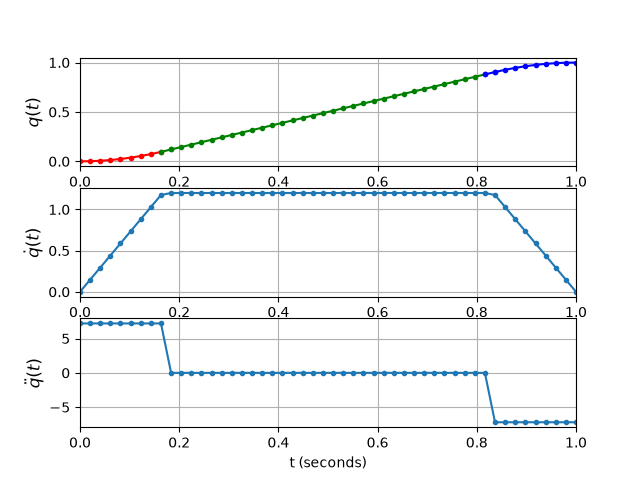

In [33]:
traj1_2 = trapezoidal(0, 1, np.linspace(0, 1, 50), V=1.2);
traj1_2.plot();

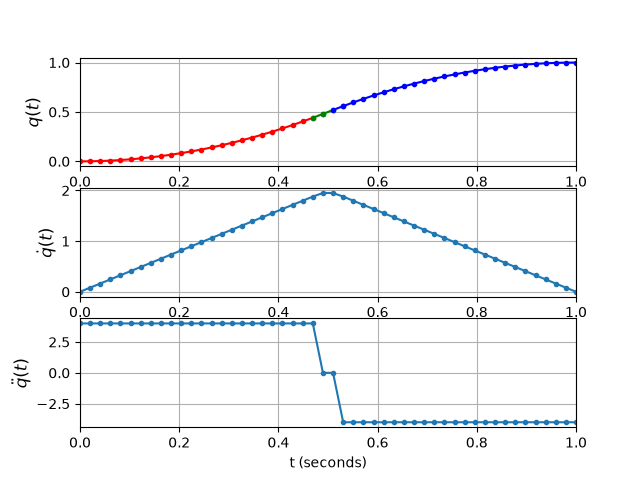

In [35]:
traj2_0 = trapezoidal(0, 1, np.linspace(0, 1, 50), V=1.95);
traj2_0.plot();

The trajectories with different max velocities compared (note that `V=2` didn't work for some time, has since been patched):

![fig-33-b-trapezoidal-plots](fig-33-b-trapezoidal-plots.png)

## 3.3.2 Multi-Axis Trajectories


Extending the scalar 1D case to vector is straightforward.
We represent the robot's configuration as a vector $\mathbf q\in\mathbb R^N$ where $N$ is the number of degrees of freedom.

In [ ]:
# 2-axis xy-type robot
# first arg is fn that generates smooth scalar trajectory
traj = mtraj(trapezoidal, [0, 2], [1, -1], 50);

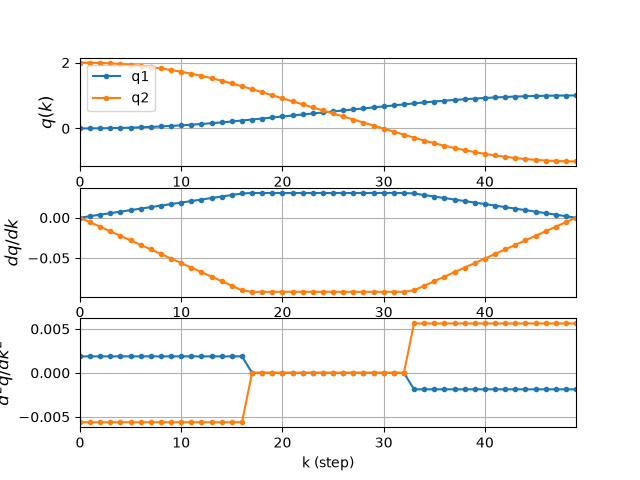

In [ ]:
traj.plot();

In [ ]:
# 3D pose
T = SE3.Rand()
q = np.hstack([T.t, T.rpy()])

array([ 0.09763,   0.4304,   0.2055,    2.777,   -1.125,    1.781])

## 3.3.3 Multi-Segment Trajectories


Often a robot needs to move through (or close to) *waypoints* on the way to the destination without stopping, (eg. to avoid obstacles, or follow piecewise-linear trajectory like welding a seam).

Let the trajectory be defined by $M$ configuration vectors $\mathbf q_k\in\mathbb R^N$ with $k=0,\ldots,M-1$ so there will be $M-1$ motion segments.


In [ ]:
via = SO2(30, unit="deg") * np.array([[-1, 1, 1, -1, -1], [1, 1, -1, -1, 1]]);
traj0 = mstraj(via.T, dt=0.2, tacc=0, qdmax=[2, 1]);

In [ ]:
# xplot(traj0.q[:, 0], traj0.q[:, 1], color="red");
plt.plot(traj0.q[:, 0], traj0.q[:, 1], color="red");

In [ ]:
traj2 = mstraj(via.T, dt=0.2, tacc=2, qdmax=[2, 1]);

In [ ]:
len(traj0), len(traj2)

## 3.3.4 Interpolation of Orientation in 3D


In [ ]:
R0 = SO3.Rz(-1) * SO3.Ry(-1);
R1 = SO3.Rz(1) * SO3.Ry(1);

In [ ]:
rpy0 = R0.rpy(); rpy1 = R1.rpy();

In [ ]:
traj = mtraj(quintic, rpy0, rpy1, 50);

In [ ]:
pose = SO3.RPY(traj.q);
len(pose)

In [ ]:
# pose.animate()
HTML(pose.animate(movie=True, dim=1.5))

In [ ]:
q0 = UnitQuaternion(R0); q1 = UnitQuaternion(R1);

In [ ]:
qtraj = q0.interp(q1, 50);
len(qtraj)

In [ ]:
# qtraj.animate()
plotvol3(new=True)  # for matplotlib/widget
HTML(qtraj.animate(movie=True, dim=1.5))

### 3.3.4.1 Direction of Rotation


In [ ]:
q0 = UnitQuaternion.Rz(-2); q1 = UnitQuaternion.Rz(2);
q = q0.interp(q1, 50);
# q.animate(dim=1.])
plotvol3(new=True)  # for matplotlib/widget
HTML(q.animate(movie=True, dim=1.5))

In [ ]:
q = q0.interp(q1, 50, shortest=True);
# q.animate()
plotvol3(new=True)  # for matplotlib/widget
HTML(q.animate(movie=True, dim=1.5))

## 3.3.5 Cartesian Motion in 3D


In [ ]:
T0 = SE3.Trans([0.4, 0.2, 0]) * SE3.RPY(0, 0, 3);
T1 = SE3.Trans([-0.4, -0.2, 0.3]) * SE3.RPY(-pi/4, pi/4, -pi/2);

In [ ]:
T0.interp(T1, 0.5)

In [ ]:
Ts = T0.interp(T1, 51);

In [ ]:
len(Ts)

In [ ]:
# Ts.animate()
plotvol3(new=True)  # for matplotlib/widget
HTML(Ts.animate(movie=True, dim=1.5))

In [ ]:
Ts[25]

In [ ]:
P = Ts.t;
P.shape

In [ ]:
xplot(P, labels="x y z");

In [ ]:
rpy = Ts.rpy();
xplot(rpy, labels="roll pitch yaw");

In [ ]:
Ts = T0.interp(T1, trapezoidal(0, 1, 50).q);

In [ ]:
Ts = ctraj(T0, T1, 50);

# 3.4 Application: Inertial Navigation


## 3.4.1 Gyroscopes


### 3.4.1.2 Estimating Orientation


In [ ]:
from imu_data import IMU
true, _ = IMU()

In [ ]:
orientation = UnitQuaternion();  # identity quaternion

In [ ]:
for w in true.omega[:-1]:
  next = orientation[-1] @ UnitQuaternion.EulerVec(w * true.dt);
  orientation.append(next);
len(orientation)

In [ ]:
# orientation.animate(time=true.t)
HTML(orientation.animate(time=true.t, movie=True, dim=1.5))

In [ ]:
xplot(true.t, orientation.rpy(), labels="roll pitch yaw");

## 3.4.4 Inertial Sensor Fusion


In [ ]:
from imu_data import IMU
true, imu = IMU()

In [ ]:
q = UnitQuaternion();
for wm in imu.gyro[:-1]:
  q.append(q[-1] @ UnitQuaternion.EulerVec(wm * imu.dt))

In [ ]:
xplot(true.t, q.angdist(true.orientation), color="red");

In [ ]:
kI = 0.2; kP = 1;
b = np.zeros(imu.gyro.shape);
qcf = UnitQuaternion();
data = zip(imu.gyro[:-1], imu.accel[:-1], imu.magno[:-1]);
for k, (wm, am, mm) in enumerate(data):
  qi = qcf[-1].inv()
  sR = np.cross(am, qi * true.g) + np.cross(mm, qi * true.B)
  wp = wm - b[k,:] + kP * sR
  qcf.append(qcf[k] @ UnitQuaternion.EulerVec(wp * imu.dt))
  b[k+1,:] = b[k,:] - kI * sR * imu.dt

In [ ]:
xplot(true.t, qcf.angdist(true.orientation), color="blue");